# Prueba Intertrimestral

**Nombre:**  
**Apellidos:**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (r2_score, mean_squared_error,
                             accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(42)

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [40]:
def rental_fee(duration_min, bike_type, is_member):
    #Calcular la tarifa
    basic_fee=1
    electric_fee=1.5
    basic_cost=0.05
    electric_cost=0.08

    if bike_type!='classic' and bike_type!='electric':
        raise ValueError("La bicicleta debe ser clasica o electrica")
    
    if bike_type=='classic':
        total=basic_fee+duration_min*basic_cost
    elif bike_type=='electric':
        total=electric_fee+duration_min*electric_cost

    if is_member:
        total *=0.8 #20% de descuento

    return round(total, 2)

In [41]:
rental_fee(20,"classic", False)

2.0

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [42]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals<threshold and total_rentals>=threshold/2:
        return "Media"
    else:
        return "Baja"

In [43]:
demand_label(100, 80)

'Alta'

In [44]:
demand_label(60, 80)

'Media'

In [45]:
demand_label(30,80)

'Baja'

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [46]:
N = 15
tripsDemo = pd.DataFrame({
    "duration_min": np.random.uniform(50, 110, N).round(2),
    "bike_type": np.random.choice(["classic", "electric"], N),
    "is_member": np.random.choice([True, False], N),
    "total_rentals": np.random.randint(0, 200, N),
})

tripsDemo["fee"] = tripsDemo.apply(lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), axis=1)
tripsDemo["demand"] = tripsDemo.apply(lambda row: demand_label(row["total_rentals"], threshold=40), axis=1)
tripsDemo.info()
tripsDemo.head(N)

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   duration_min   15 non-null     float64
 1   bike_type      15 non-null     str    
 2   is_member      15 non-null     bool   
 3   total_rentals  15 non-null     int32  
 4   fee            15 non-null     float64
 5   demand         15 non-null     str    
dtypes: bool(1), float64(2), int32(1), str(2)
memory usage: 687.0 bytes


,duration_min,bike_type,is_member,total_rentals,fee,demand
0,72.47,classic,False,50,4.62,Alta
1,107.04,classic,False,134,6.35,Alta
2,93.92,electric,True,20,7.21,Media
3,85.92,electric,False,72,8.37,Alta
4,59.36,electric,False,166,6.25,Alta
5,59.36,classic,True,17,3.17,Baja
6,53.49,electric,False,131,5.78,Alta
7,101.97,classic,True,88,4.88,Alta
8,86.07,classic,False,59,5.30,Alta
9,92.48,classic,True,13,4.50,Baja


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [57]:
class MicromobilityTools():
    def __init__(self):
        self.df = None

    def demand_label(self, total_rentals, threshold):
        if total_rentals >= threshold:
            self.df["demand"] = "Alta"
        elif total_rentals<threshold and total_rentals>=threshold/2:
            self.df["demand"] = "Media"
        else:
            self.df["demand"] = "Baja"

    def rental_fee(self, duration_min, bike_type, is_member):
        #Calcular la tarifa
        basic_fee=1
        electric_fee=1.5
        basic_cost=0.05
        electric_cost=0.08

        if bike_type!='classic' and bike_type!='electric':
            raise ValueError("La bicicleta debe ser clasica o electrica")
        
        if bike_type=='classic':
            total=basic_fee+duration_min*basic_cost
        elif bike_type=='electric':
            total=electric_fee+duration_min*electric_cost

        if is_member:
            total *=0.8 #20% de descuento

        self.df["fee"] = round(total, 2)

## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [47]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
mobilityData.head(5)

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


In [48]:
mobilityData.shape

(17520, 23)

En la solución podemos ver que 17520 son las filas y que 23 son las columnas del dataframe

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [49]:
def describeData(dataFrame):
    print("Tipo de datos de cada columna:")
    print(dataFrame.dtypes)
    print("\nNúmero de nulos por columna:")
    print(dataFrame.isnull().sum())
    print("\nPorcentaje de nulos por columna:")
    print((dataFrame.isnull().sum() / len(dataFrame)) * 100)

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [50]:
describeData(mobilityData)

Tipo de datos de cada columna:
datetime               str
year                 int64
month                int64
day                  int64
hour                 int64
weekday              int64
season                 str
is_holiday           int64
is_weekend           int64
is_workingday        int64
weather                str
temp_c             float64
humidity           float64
wind_kmh           float64
precip_mm          float64
casual_users         int64
member_users         int64
total_rentals        int64
avg_trip_min       float64
avg_distance_km    float64
electric_share     float64
revenue_eur        float64
high_demand          int64
dtype: object

Número de nulos por columna:
datetime             0
year                 0
month                0
day                  0
hour                 0
weekday              0
season               0
is_holiday           0
is_weekend           0
is_workingday        0
weather              0
temp_c               0
humidity           224
wind_

Como podemos ver con la función cada variable es de distintos tipos como str (datetime, season y waether), float64 (temp_c, humidity, wind_kmh, precip_mm, avg_trip_min, avg_dist_km, electric_share, revenue_eur) e int64 para el resto de las variables. De estas podemos ver existen nulos en las variables humidity, wind_kmh, avg_trip_min y electric_share. Sin embargo, podemos ver en porcentaje que mninguno de los valores que faltan son más del 1.5% del dataframe por lo que no son significativos. 

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


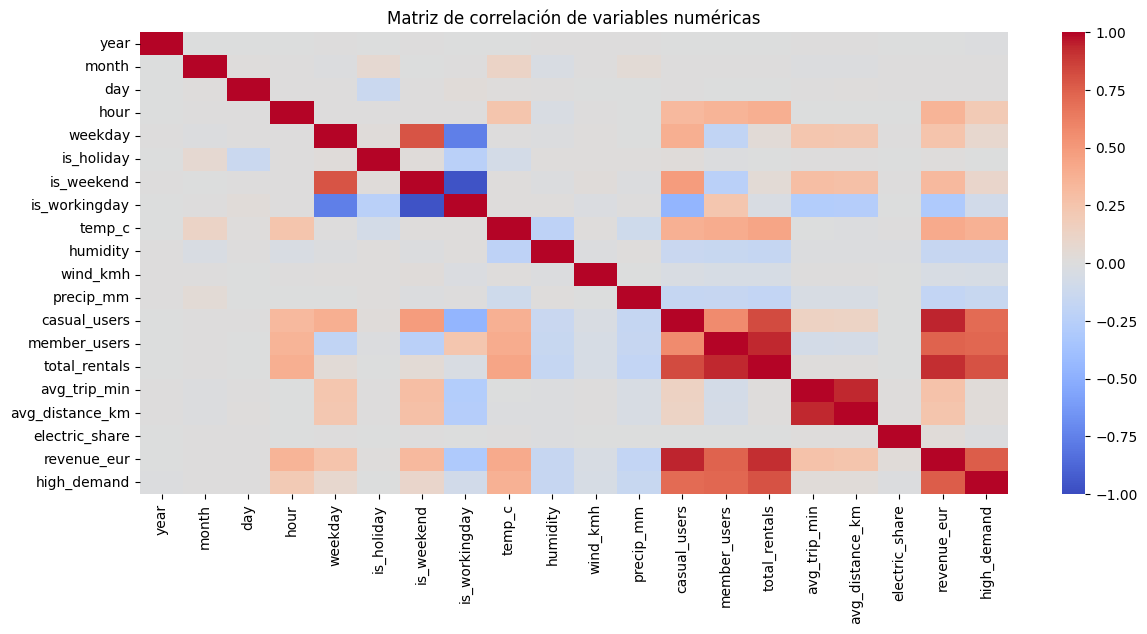

In [51]:
#1. Gráfico de correlación
corr = mobilityData.select_dtypes(include="number").corr()
plt.figure(figsize=(14, 6))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, annot=False)
plt.title("Matriz de correlación de variables numéricas")
plt.show()

Mayor: (np.int64(18), np.int64(0)) | Menor: (np.int64(1), np.int64(0))


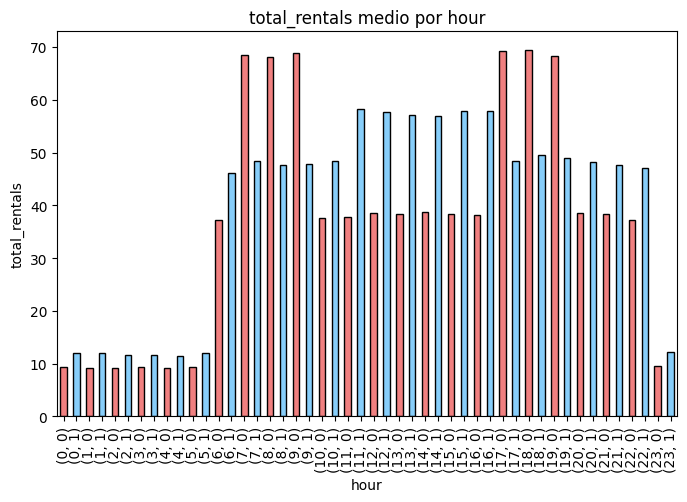

In [52]:
#2. Gráficoo de total_rentals por hour, separando fin de semana y laborable
cat_col = "hour"
valor_col = "total_rentals"
media = mobilityData.groupby([cat_col, "is_weekend"])[valor_col].mean()
print("Mayor:", media.idxmax(), "| Menor:", media.idxmin())
media.plot(kind="bar", color=["lightcoral", "lightskyblue"], edgecolor="black", figsize=(8, 5))
plt.title(f"{valor_col} medio por {cat_col}") 
plt.ylabel(valor_col)
plt.xlabel(mobilityData[cat_col].name)
plt.show()

Estos gráficos nos permiten ver y variables que están muy relacionadas entre sñi, en el heatmap podemos ver que avergae_km y average_duracion tienen una relación muy fuerte positiva (a más km más duración). También vemos que el revenue viene muy relacionado con los casual_users y con total_demand, cosa que también encaja. 

Por otro lado, vemos en el gráfico de demanda por horas que durante los días lectivos la demanda se concentra en las horas de ida y vuelta de la oficina (7-9am) y (17-19) mientras que el fin de semana están más distribuidas a lo largo de todo el día

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [20]:
targetVar = "total_rentals"  # CAMBIA
predictoras = ["hour", "is_weekend", "temp_c", "wind_kmh", "precip_mm"]
datos = mobilityData[[targetVar] + predictoras].dropna()
X = datos[predictoras]
y = datos[targetVar]
X.shape, y.shape

((17378, 5), (17378,))

b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

(12164, 5) (5214, 5)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [26]:
modelo=LinearRegression()
modelo.fit(X_train, y_train)
pred_train=modelo.predict(X_train)
pred=modelo.predict(X_test)
print({"R2": r2_score(y_test, pred), "MSE": mean_squared_error(y_test, pred),"RMSE": np.sqrt(mean_squared_error(y_test, pred))})
print(r2_score(y_train, pred_train), r2_score(y_test, pred))

{'R2': 0.306662202675552, 'MSE': 415.7503194972311, 'RMSE': np.float64(20.38995633877697)}
0.2964463531135929 0.306662202675552


Tras haber entrenado el LinearRegression podemos ver, tras hacer la prueba con el bloque de test que los resultados son muy malos ya que el R^2 solo es 0.31, lo que implica que el modelo no predice bien los datos de test. Al ver esto, luego he comprobado si en el caso de los de train lo había hecho mal también (ya que si lo habíahecho bien podría venir de overfitting) pero efectivamente no era así y he visto que la calidad del modelo es muy mala tanto en train como en test por lo que este tipo de modelos no son los ideales para este problema

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [27]:
modelo2=RandomForestRegressor(n_estimators=100, random_state=42)
modelo2.fit(X_train, y_train)
pred_train2=modelo2.predict(X_train)
pred2=modelo2.predict(X_test)
print({"R2": r2_score(y_test, pred2), "MSE": mean_squared_error(y_test, pred2),"RMSE": np.sqrt(mean_squared_error(y_test, pred2))})
print(r2_score(y_train, pred_train2), r2_score(y_test, pred2))

{'R2': 0.8741729616309571, 'MSE': 75.45042489417348, 'RMSE': np.float64(8.686220403269392)}
0.9818662590270824 0.8741729616309571


En este caso podemos ver que el modelo ha mejorado mucho con respecto al modelo lineal ya que ahora R^2 es 0.87 en test, lo que implica que la demanda sí que se está estimando bien usando este modelo. Por otro lado, comparandolo con los resultados del train, vemos que quizás hay un poco de ovrefitting ya que el R^2 en train es del 0.98, aunque como en el test el resultado es bueno también no parece algo importante. 

Por otro lado, cosa que antes no había destacado del modelo lineal es que el MSE es bastante más bajo también, cosa que tiene sentido ya que al aumentar el R^2 hemos mejorado la precisión y por ello el error se ha disminuido, pasando de 415.75 a 75.45 que es una diferencia bastante grande como error cuadrático medio (MSE)

En este caso, el RandomForest está siendo capaz de captar las relaciones entre los eleemtnos que no son lineales, es decir rwlaciones entre las variables que existen (como podríamos predecir sin los modelos) pero que no necesariamente se basan en pesos concretos por variable (como pondera el LinearRegression)

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [28]:
mobilityData["high_demand"].value_counts(normalize=True)

high_demand
0    0.688984
1    0.311016
Name: proportion, dtype: float64

b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [36]:
predictores = ["hour", "is_weekend", "temp_c", "wind_kmh", "precip_mm"]
datos_c=mobilityData[["high_demand"] + predictores].dropna()
Xc, yc = datos_c[predictores], datos_c["high_demand"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3, random_state=42, stratify=yc)

scaler = StandardScaler()
Xc_train_s = scaler.fit_transform(Xc_train)
Xc_test_s = scaler.transform(Xc_test)

log = LogisticRegression(max_iter=1000)
log.fit(Xc_train_s, yc_train)
yc_pred = log.predict(Xc_test_s)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy: 0.7493
Proporción clase mayoritaria: 0.6889
              precision    recall  f1-score   support

           0       0.77      0.90      0.83      3592
           1       0.65      0.41      0.51      1622

    accuracy                           0.75      5214
   macro avg       0.71      0.66      0.67      5214
weighted avg       0.74      0.75      0.73      5214



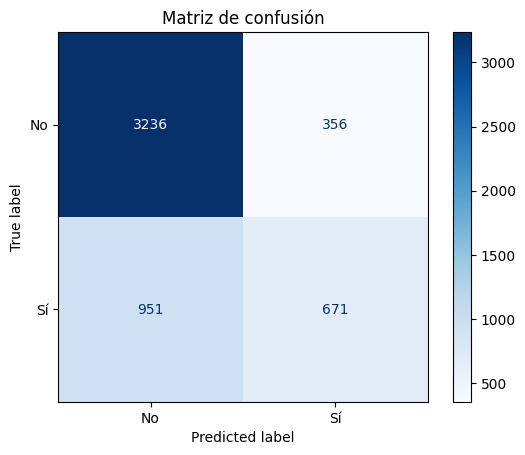

In [37]:
print("Accuracy:", round(accuracy_score(yc_test, yc_pred), 4))
print("Proporción clase mayoritaria:", round(yc_test.value_counts(normalize=True).max(), 4))
print(classification_report(yc_test, yc_pred))
ConfusionMatrixDisplay(confusion_matrix(yc_test, yc_pred), display_labels=["No", "Sí"]).plot(cmap="Blues")
plt.title("Matriz de confusión"); plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


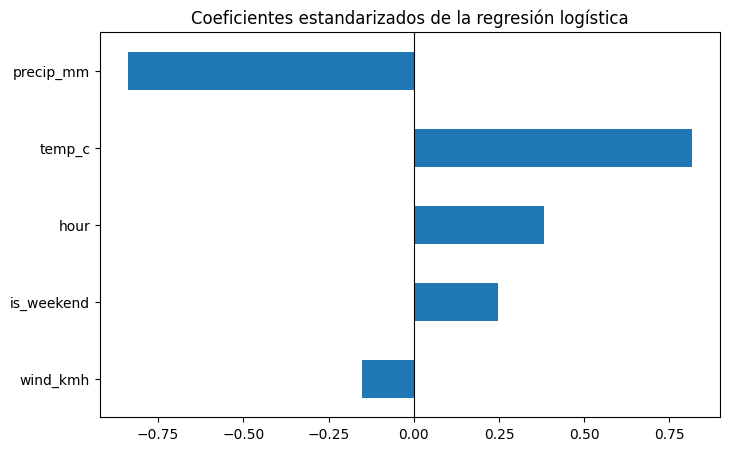

precip_mm    -0.838094
temp_c        0.815267
hour          0.381092
is_weekend    0.246333
wind_kmh     -0.150625
dtype: float64

In [38]:
coefs = pd.Series(log.coef_[0], index=predictores).sort_values(key=abs)
coefs.plot(kind="barh", figsize=(8, 5), title="Coeficientes estandarizados de la regresión logística")
plt.axvline(0, color="black", linewidth=0.8); plt.show()
coefs.sort_values(key=abs, ascending=False)

Para este modelo, he decidido usar las mismas variables que usé en el modelo anterior para predecir los total_rentals ya que son dos variables que van a tener mucha relación entre sí y por entender bien cuáles son los elementos que más las determinan. Como podemos ver en el gráfico de importancia de las variables, la primera (y más importante) es la precipitación, que en este caso tiene un efecto contrario (cuando aumenta la lluvia se usan menos bicicletas) cosa que tiene mucho sentido ya que con lluvia es más dificil y más incomodo ir montando en bici porque acabas mojado. 
Luego, la temperatura sí que tiene relación directa, a medida que hace más calor también es más agradable ir en bicileta por lo que aumenta la demanda. Luego la hora y el is_weekend afectan también ya que se cogen más bicicletas a medida que aumenta el día (hora más alta) y cuando es fin de semana. 
El viento también afecta negativamente al igual que la lluvia pero mucho menos que esta ya que afecta menos el viento que la lluvia en importancia para el modelo

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Según los modelos que he hecho se ha podido confirmar que las variables que más afectan a la demanda de bicicletas (tanto total_rentals como high_demand) son principalmente la lluvia y la temperatura ya que son aquellas que provocan unos cambios más imprtantes en la demanda. Como podíamos intuir antes, se ha confirmado que el efecto de estas es contrario, por un lado la lluvia reduce mucho la demanda y por otro lado l atemperatura la aumenta mucho cosa que encaja con lo que estimábamos antes de hacer los modelos. 

Por otro lado, he visto también que la demanda no sigue una relación lineal con estas variables explicativas ya que se ha comprobado que el peor modelo es el de LinearRegression y el mejor de ellos es el RandomForest por lo que las relaciones entre la demanda y las distintas variables no se basan en un peso fijo para cada variable (que sería el modelo lineal)

Si tuviésemos más datos podríamos establecer si esto se debe al clima propio de la ciudad o si es un patrón que es global para todas las ciudades. Es decir, si comparamos Madrid (donde no suele llover) con Galicia (donde suele llover) podríamos establecer hasta qué punto las características y las costumbres de las personas de cada ciudad acaban teniedno impacto, ya que en Galicia es posible que las personas estén más acostumbradas a la lluvia y por ello serían capaces de coger las biciletas más con agua que en Madrid. 